In [20]:
import logging
import os
from pathlib import Path
from dotenv import load_dotenv

# ==========================================
# 1. DEFINE PROJECT PATH
# ==========================================

# Parent folder of current working directory
project_dir = Path.cwd().parent

# Log directory
log_dir = project_dir / "log"
log_dir.mkdir(parents=True, exist_ok=True)

# Log file
log_file = log_dir / "app.log"

# Environment file
env_file = project_dir / ".env"

# ==========================================
# 2. CONFIGURE LOGGING
# ==========================================

logging.basicConfig(
    filename=log_file,
    filemode="a",
    format="%(asctime)s [%(levelname)s] %(message)s",
    level=logging.INFO,
    force=True
)

logging.info("Application started successfully")

# ==========================================
# 3. LOAD ENVIRONMENT VARIABLES
# ==========================================

if env_file.exists():
    load_dotenv(dotenv_path=env_file)
    logging.info(".env file loaded")
else:
    logging.warning(".env file not found: %s", env_file)

# ==========================================
# 4. GET GCP CONFIGURATION
# ==========================================

GCP_PROJECT_ID = os.getenv("GCP_PROJECT_ID")
BUCKET_NAME = os.getenv("BUCKET_NAME")
LOCATION = os.getenv("LOCATION")

# ==========================================
# 5. VALIDATE CONFIGURATION
# ==========================================

print("Project directory:", project_dir)
print("Log file:", log_file)
print("Environment file:", env_file)

print("GCP Project ID:", GCP_PROJECT_ID)
print("Bucket Name:", BUCKET_NAME)
print("Location:", LOCATION)

logging.info("Configuration loading completed")


Project directory: c:\Users\kikwe\Group_9_Module_3_Project-feature-CLEAN_CODE\Group_9_Module_3_Project-feature-CLEAN_CODE
Log file: c:\Users\kikwe\Group_9_Module_3_Project-feature-CLEAN_CODE\Group_9_Module_3_Project-feature-CLEAN_CODE\log\app.log
Environment file: c:\Users\kikwe\Group_9_Module_3_Project-feature-CLEAN_CODE\Group_9_Module_3_Project-feature-CLEAN_CODE\.env
GCP Project ID: None
Bucket Name: None
Location: None


In [21]:
logging.debug("Debug test")
logging.info("Info test")
logging.warning("Warning test")
logging.error("Error test")

In [22]:
import csv
from pathlib import Path
from zipfile import ZipFile

zip_path = Path(r"C:\Users\kikwe\Downloads\Module 3 Project Datasets (2).zip")

if not zip_path.is_file():
    raise FileNotFoundError(f"ZIP file not found: {zip_path}")

output_dir = Path.cwd() / "zip_inventory"
output_dir.mkdir(parents=True, exist_ok=True)
csv_path = output_dir / "zip_contents.csv"

with ZipFile(zip_path) as archive:
    rows = [
        [
            Path(item.filename).suffix.lower() or "[no extension]",
            item.filename,
            item.file_size,
        ]
        for item in archive.infolist()
        if not item.is_dir()
    ]

rows.sort(key=lambda row: (row[0], row[1].lower()))

with csv_path.open("w", newline="", encoding="utf-8-sig") as csv_file:
    writer = csv.writer(csv_file)
    writer.writerow(["file_type", "file_name", "size_bytes"])
    writer.writerows(rows)

print(f"Saved CSV to: {csv_path}")


Saved CSV to: c:\Users\kikwe\Group_9_Module_3_Project-feature-CLEAN_CODE\Group_9_Module_3_Project-feature-CLEAN_CODE\notebooks\zip_inventory\zip_contents.csv


In [23]:
import csv
from pathlib import Path
from zipfile import ZipFile

zip_path = Path(r"C:\Users\kikwe\Downloads\Module 3 Project Datasets (2).zip") # Change this path
folder_to_read = Path(r"c:\Users\kikwe\Downloads\Fred add files")  # Change this path

if not zip_path.is_file():
    raise FileNotFoundError(f"ZIP file not found: {zip_path}")

if not folder_to_read.is_dir():
    raise NotADirectoryError(f"Folder not found: {folder_to_read}")

output_dir = Path.cwd() / "zip_inventory"
output_dir.mkdir(parents=True, exist_ok=True)
csv_path = output_dir / "zip_contents.csv"

rows = []

# Add files from the ZIP
with ZipFile(zip_path) as archive:
    for item in archive.infolist():
        if not item.is_dir():
            rows.append([
                "ZIP",
                Path(item.filename).suffix.lower() or "[no extension]",
                item.filename,
                item.file_size,
            ])

# Add files from the folder and its subfolders
for file_path in folder_to_read.rglob("*"):
    if file_path.is_file():
        rows.append([
            "Folder",
            file_path.suffix.lower() or "[no extension]",
            str(file_path.relative_to(folder_to_read)),
            file_path.stat().st_size,
        ])

rows.sort(key=lambda row: (row[1], row[0], row[2].lower()))

with csv_path.open("w", newline="", encoding="utf-8-sig") as csv_file:
    writer = csv.writer(csv_file)
    writer.writerow(["source", "file_type", "file_name", "size_bytes"])
    writer.writerows(rows)

print(f"Saved {len(rows)} entries to: {csv_path}")

Saved 103 entries to: c:\Users\kikwe\Group_9_Module_3_Project-feature-CLEAN_CODE\Group_9_Module_3_Project-feature-CLEAN_CODE\notebooks\zip_inventory\zip_contents.csv


In [24]:
import sys
print(sys.executable)

c:\Users\kikwe\Group_9_Module_3_Project-feature-CLEAN_CODE\dsai-m3\Scripts\python.exe


In [25]:
# Data Ingestion

from pathlib import Path
import numpy as np
import pandas as pd
import yfinance as yf

# ==========================================
# 1. CREATE DATA DIRECTORY
# ==========================================

data_dir = Path("../data")
data_dir.mkdir(parents=True, exist_ok=True)

# ==========================================
# 2. DOWNLOAD HISTORICAL STOCK DATA
# ==========================================

df = yf.download(
    "SPY",
    start="2010-01-01",
    end="2026-01-01",
    auto_adjust=True,
    progress=False
)

if df.empty:
    raise ValueError("No SPY data downloaded")

if isinstance(df.columns, pd.MultiIndex):
    df.columns = df.columns.get_level_values(0)

df = df.sort_index().copy()

# ==========================================
# 3. FEATURE ENGINEERING
# ==========================================

close = df["Close"]

# Daily return
df["Daily_Return"] = close.pct_change()

# Simple moving averages
df["SMA_20"] = close.rolling(20).mean()
df["SMA_50"] = close.rolling(50).mean()

# Price relative to moving averages
df["Price_SMA20_Ratio"] = close / df["SMA_20"] - 1
df["Price_SMA50_Ratio"] = close / df["SMA_50"] - 1

# Historical daily volatility
df["Volatility_20"] = (
    df["Daily_Return"].rolling(20).std()
)

# ==========================================
# 4. RSI (WILDER SMOOTHING)
# ==========================================

delta = close.diff()

gain = delta.clip(lower=0)
loss = -delta.clip(upper=0)

# Wilder-style exponentially smoothed RSI
avg_gain = gain.ewm(
    alpha=1/14,
    adjust=False,
    min_periods=14
).mean()

avg_loss = loss.ewm(
    alpha=1/14,
    adjust=False,
    min_periods=14
).mean()

rs = avg_gain / avg_loss

df["RSI_14"] = 100 - 100 / (1 + rs)

# Handle zero-loss and flat-price cases
df.loc[(avg_loss == 0) & (avg_gain > 0),
       "RSI_14"] = 100
df.loc[(avg_loss == 0) & (avg_gain == 0),
       "RSI_14"] = 50

# ==========================================
# 5. CREATE PREDICTION TARGET
# ==========================================

# Predict next trading-day return
df["Target_Next_Return"] = (
    close.shift(-1) / close - 1
)

# Binary classification:
# 1 = Next day higher
# 0 = Next day unchanged or lower
df["Target_Up"] = (
    df["Target_Next_Return"] > 0
).astype(int)

# ==========================================
# 6. REMOVE MISSING TRAINING VALUES
# ==========================================

feature_cols = [
    "Daily_Return",
    "SMA_20",
    "SMA_50",
    "Price_SMA20_Ratio",
    "Price_SMA50_Ratio",
    "Volatility_20",
    "RSI_14"
]

df = df.replace([np.inf, -np.inf], np.nan)

df = df.dropna(
    subset=feature_cols + ["Target_Next_Return"]
)

# ==========================================
# 7. EXPORT CSV
# ==========================================

output_file = data_dir / "spy_features.csv"

df.to_csv(output_file, index_label="Date")

print(f"Saved: {output_file}")
print(f"Records: {len(df):,}")
print(f"Period: {df.index.min()} to {df.index.max()}")
print(df.tail())


Saved: ..\data\spy_features.csv
Records: 3,974
Period: 2010-03-16 00:00:00 to 2025-12-30 00:00:00
Price            Close        High         Low        Open    Volume  \
Date                                                                   
2025-12-23  682.628235  682.866365  678.569906  678.619507  64840000   
2025-12-24  685.029480  685.476005  682.469458  682.618320  39445600   
2025-12-26  684.959961  686.299474  683.928043  685.287420  41613300   
2025-12-29  682.519043  683.858617  680.752870  682.211448  62559500   
2025-12-30  681.685547  683.223522  681.258887  682.122139  47160700   

Price       Daily_Return      SMA_20      SMA_50  Price_SMA20_Ratio  \
Date                                                                  
2025-12-23      0.004571  675.014877  669.126180           0.011279   
2025-12-24      0.003518  675.875592  669.723538           0.013544   
2025-12-26     -0.000101  676.502316  670.261332           0.012502   
2025-12-29     -0.003564  676.823477  670.

In [26]:
#Target Definition & Class Imbalance

# Future 5-day return (using negative shift for the future target)
df["Future_Return_5d"] = df["Close"].pct_change(5).shift(-5)

def define_target(ret):
  if ret > 0.01:
  # Buy (Class 1)
    return 1
  elif ret < -0.01:
  # Sell (Class -1 or 2)
    return -1
  else:
  # Hold (Class 0)
    return 0

df["Target"] = df["Future_Return_5d"].apply(define_target)
df.dropna(inplace=True)

# Save the final dataset with targets included
final_output = data_dir / "spy_labeled_features.csv"
df.to_csv(final_output)

# Check class proportions
print(df["Target"].value_counts(normalize=True))

Target
 0    0.424036
 1    0.361552
-1    0.214412
Name: proportion, dtype: float64


In [27]:
from sklearn.model_selection import TimeSeriesSplit
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import classification_report

# Define features and target
feature_cols = ["Daily_Return", "SMA_20", "SMA_50", "Volatility_20", "RSI_14"]
X = df[feature_cols]
y = df["Target"]

# Time-series split (crucial to prevent look-ahead bias)
train_mask = df.index < "2023-01-01"
X_train, y_train = X[train_mask], y[train_mask]
X_test, y_test = X[~train_mask], y[~train_mask]

# Train model (class_weight="balanced" helps if classes are imbalanced)
model = RandomForestClassifier(n_estimators=100, class_weight="balanced", random_state=42)
model.fit(X_train, y_train)

# Evaluate
predictions = model.predict(X_test)
print(classification_report(y_test, predictions))

              precision    recall  f1-score   support

          -1       0.20      0.80      0.32       147
           0       0.51      0.12      0.20       304
           1       0.50      0.16      0.24       295

    accuracy                           0.27       746
   macro avg       0.40      0.36      0.25       746
weighted avg       0.44      0.27      0.24       746



In [28]:
import numpy as np
import pandas as pd
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import classification_report, accuracy_score

feature_cols = ["Daily_Return", "SMA_20", "SMA_50", "Volatility_20", "RSI_14"]
X = df[feature_cols]
y = df["Target"]

split_date = pd.Timestamp("2023-01-01")
train_positions = np.flatnonzero(df.index < split_date)
test_positions = np.flatnonzero(df.index >= split_date)

# Exclude the final five training rows because their targets look into the test period
train_positions = train_positions[:-5]

X_train, y_train = X.iloc[train_positions], y.iloc[train_positions]
X_test, y_test = X.iloc[test_positions], y.iloc[test_positions]

model = RandomForestClassifier(
    n_estimators=100,
    class_weight="balanced",
    random_state=42
)
model.fit(X_train, y_train)

predictions = model.predict(X_test)

print("Model accuracy:", accuracy_score(y_test, predictions))
print(classification_report(y_test, predictions))

# Compare against predicting the most common training class every time
baseline_class = y_train.mode().iloc[0]
baseline_predictions = np.full(len(y_test), baseline_class)
print("Baseline accuracy:", accuracy_score(y_test, baseline_predictions))

Model accuracy: 0.25603217158176944
              precision    recall  f1-score   support

          -1       0.20      0.78      0.32       147
           0       0.49      0.12      0.19       304
           1       0.43      0.14      0.21       295

    accuracy                           0.26       746
   macro avg       0.37      0.35      0.24       746
weighted avg       0.41      0.26      0.22       746

Baseline accuracy: 0.4075067024128686


In [29]:
import pandas as pd
from sklearn.model_selection import TimeSeriesSplit
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score, balanced_accuracy_score, f1_score

feature_cols = ["Daily_Return", "SMA_20", "SMA_50", "Volatility_20", "RSI_14"]
X = df[feature_cols]
y = df["Target"]

# The five-row gap prevents five-day target windows from crossing each split.
splitter = TimeSeriesSplit(n_splits=5, gap=5)
results = []

for fold, (train_idx, test_idx) in enumerate(splitter.split(X), start=1):
    X_train, X_test = X.iloc[train_idx], X.iloc[test_idx]
    y_train, y_test = y.iloc[train_idx], y.iloc[test_idx]

    model = RandomForestClassifier(
        n_estimators=100,
        class_weight="balanced",
        random_state=42
    )
    model.fit(X_train, y_train)
    predictions = model.predict(X_test)

    baseline_class = y_train.mode().iloc[0]
    baseline_predictions = [baseline_class] * len(y_test)

    results.append({
        "fold": fold,
        "test_start": df.index[test_idx[0]].date(),
        "test_end": df.index[test_idx[-1]].date(),
        "model_accuracy": accuracy_score(y_test, predictions),
        "baseline_accuracy": accuracy_score(y_test, baseline_predictions),
        "model_balanced_accuracy": balanced_accuracy_score(y_test, predictions),
        "model_macro_f1": f1_score(y_test, predictions, average="macro", zero_division=0),
    })

results_df = pd.DataFrame(results)
print(results_df.to_string(index=False))
print("\nAverage scores:")
print(results_df.select_dtypes("number").mean())

 fold test_start   test_end  model_accuracy  baseline_accuracy  model_balanced_accuracy  model_macro_f1
    1 2012-11-01 2015-06-18        0.245083           0.334342                 0.320978        0.232036
    2 2015-06-19 2018-02-01        0.372163           0.559758                 0.332666        0.338572
    3 2018-02-02 2020-09-17        0.431165           0.370651                 0.378839        0.318642
    4 2020-09-18 2023-05-04        0.276853           0.350983                 0.295924        0.264037
    5 2023-05-05 2025-12-22        0.252648           0.411498                 0.353198        0.224819

Average scores:
fold                       3.000000
model_accuracy             0.315582
baseline_accuracy          0.405446
model_balanced_accuracy    0.336321
model_macro_f1             0.275621
dtype: float64


In [30]:
feature_cols = [
    "Daily_Return",
    "Price_SMA20_Ratio",
    "Price_SMA50_Ratio",
    "Volatility_20",
    "RSI_14",
]

In [31]:
import numpy as np
import pandas as pd
from sklearn.model_selection import TimeSeriesSplit
from sklearn.ensemble import RandomForestClassifier

feature_cols = [
    "Daily_Return",
    "Price_SMA20_Ratio",
    "Price_SMA50_Ratio",
    "Volatility_20",
    "RSI_14",
]
X = df[feature_cols]
y = df["Target"]

splitter = TimeSeriesSplit(n_splits=5, gap=5)
oof_predictions = pd.Series(np.nan, index=X.index)
for train_idx, test_idx in splitter.split(X):
    model = RandomForestClassifier(
        n_estimators=100,
        class_weight="balanced",
        random_state=42,
    )
    model.fit(X.iloc[train_idx], y.iloc[train_idx])
    oof_predictions.iloc[test_idx] = model.predict(X.iloc[test_idx])

trade_positions = np.flatnonzero(oof_predictions.notna().to_numpy())[::5]
signals = oof_predictions.iloc[trade_positions].astype(int).to_numpy()
future_returns = df["Future_Return_5d"].iloc[trade_positions].to_numpy()
cost_per_side = 0.0005

def simulate_long_cash(actions, period_returns):
    portfolio_returns = []
    invested = 0
    for action, market_return in zip(actions, period_returns):
        target_position = 1 if action == 1 else 0 if action == -1 else invested
        turnover = abs(target_position - invested)
        net_return = (1 + target_position * market_return) * (1 - cost_per_side) ** turnover - 1
        portfolio_returns.append(net_return)
        invested = target_position
    if portfolio_returns and invested:
        portfolio_returns[-1] = (1 + portfolio_returns[-1]) * (1 - cost_per_side) - 1
    return np.asarray(portfolio_returns)

strategy_returns = simulate_long_cash(signals, future_returns)
buy_hold_returns = simulate_long_cash(
    np.ones(len(future_returns), dtype=int), future_returns
)
print(f"Out-of-sample periods: {len(trade_positions)}")
print("BUY enters/maintains long; SELL exits to cash; HOLD retains the current position.")
print(f"Illustrative cost: {cost_per_side:.2%} per side")
print(f"Model strategy compounded return: {np.prod(1 + strategy_returns) - 1:.2%}")
print(f"Buy-and-hold compounded return: {np.prod(1 + buy_hold_returns) - 1:.2%}")


Out-of-sample periods: 661
BUY enters/maintains long; SELL exits to cash; HOLD retains the current position.
Illustrative cost: 0.05% per side
Model strategy compounded return: 143.79%
Buy-and-hold compounded return: 506.98%


In [32]:
import numpy as np
import pandas as pd
from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import TimeSeriesSplit

feature_cols = [
    "Daily_Return",
    "Price_SMA20_Ratio",
    "Price_SMA50_Ratio",
    "Volatility_20",
    "RSI_14",
]
X = df[feature_cols]
y = df["Target"]

# Generate out-of-fold predictions; each prediction is from a model that did not train on that date.
oof_predictions = pd.Series(np.nan, index=X.index)
splitter = TimeSeriesSplit(n_splits=5, gap=5)
for fold, (train_idx, test_idx) in enumerate(splitter.split(X)):
    # Safely retrieve parameters or use default if 'results' is not defined
    # params = results[fold]["best_parameters"]
    try:
        params = results[fold].get("best_parameters", {})
    except (NameError, KeyError):
        params = {}
    model = RandomForestClassifier(
        **params,
        class_weight="balanced",
        random_state=42,
    )
    model.fit(X.iloc[train_idx], y.iloc[train_idx])
    oof_predictions.iloc[test_idx] = model.predict(X.iloc[test_idx])

# Sample non-overlapping five-trading-day return periods.
positions = np.flatnonzero(oof_predictions.notna().to_numpy())[::5]
signals = oof_predictions.iloc[positions].astype(int).to_numpy()
future_returns = df["Future_Return_5d"].iloc[positions].to_numpy()
cost_per_side = 0.0005

def simulate_long_cash(actions, period_returns):
    """Apply BUY/SELL/HOLD actions, charging costs when position changes."""
    portfolio_returns = []
    invested = 0
    for action, market_return in zip(actions, period_returns):
        if action == 1:
            target_position = 1
        elif action == -1:
            target_position = 0
        else:
            target_position = invested
        turnover = abs(target_position - invested)
        net_return = ((1 + target_position * market_return) * (1 - cost_per_side) ** turnover - 1)
        portfolio_returns.append(net_return)
        invested = target_position
    if portfolio_returns and invested:
        portfolio_returns[-1] = (
            (1 + portfolio_returns[-1]) * (1 - cost_per_side) - 1
        )
    return np.asarray(portfolio_returns)

# Rule benchmark: buy in an uptrend and exit when any trend condition reverses.
close = df["Close"]
macd_line = close.ewm(span=12, adjust=False).mean() - close.ewm(
    span=26, adjust=False
).mean()
macd_signal = macd_line.ewm(span=9, adjust=False).mean()
sampled_close = close.iloc[positions].to_numpy()
sampled_sma50 = df["SMA_50"].iloc[positions].to_numpy()
sampled_rsi = df["RSI_14"].iloc[positions].to_numpy()
sampled_macd = macd_line.iloc[positions].to_numpy()
sampled_macd_signal = macd_signal.iloc[positions].to_numpy()
rule_buy = (
    (sampled_close > sampled_sma50)
    & (sampled_rsi > 50)
    & (sampled_macd > sampled_macd_signal)
)
rule_sell = (
    (sampled_close < sampled_sma50)
    | (sampled_rsi < 50)
    | (sampled_macd < sampled_macd_signal)
)
rule_actions = np.where(rule_buy, 1, np.where(rule_sell, -1, 0))

model_returns = simulate_long_cash(signals, future_returns)
rule_returns = simulate_long_cash(rule_actions, future_returns)
buy_hold_returns = simulate_long_cash(
    np.ones(len(future_returns), dtype=int), future_returns
)

def summarize_strategy(name, returns):
    equity = np.concatenate(([1.0], np.cumprod(1 + returns)))
    drawdown = equity / np.maximum.accumulate(equity) - 1
    return {
        "strategy": name,
        "compounded_return": equity[-1] - 1,
        "max_drawdown": drawdown.min(),
    }

summary = pd.DataFrame([
    summarize_strategy("Random Forest (long-or-cash)", model_returns),
    summarize_strategy("RSI/MACD/SMA rules (long-or-cash)", rule_returns),
    summarize_strategy("Buy and hold", buy_hold_returns),
])
print(f"Out-of-sample five-day periods: {len(positions)}")
print(f"Illustrative transaction cost: {cost_per_side:.2%} per side")
print("HOLD retains the prior position; SELL exits to cash; short positions are not used.")
print(summary.to_string(index=False, formatters={
    "compounded_return": "{:.2%}".format,
    "max_drawdown": "{:.2%}".format,
}))


Out-of-sample five-day periods: 661
Illustrative transaction cost: 0.05% per side
HOLD retains the prior position; SELL exits to cash; short positions are not used.
                         strategy compounded_return max_drawdown
     Random Forest (long-or-cash)           143.79%      -19.94%
RSI/MACD/SMA rules (long-or-cash)            82.86%      -13.93%
                     Buy and hold           506.98%      -29.07%


Strategy max drawdown: -19.94%
Buy-and-hold max drawdown: -29.07%


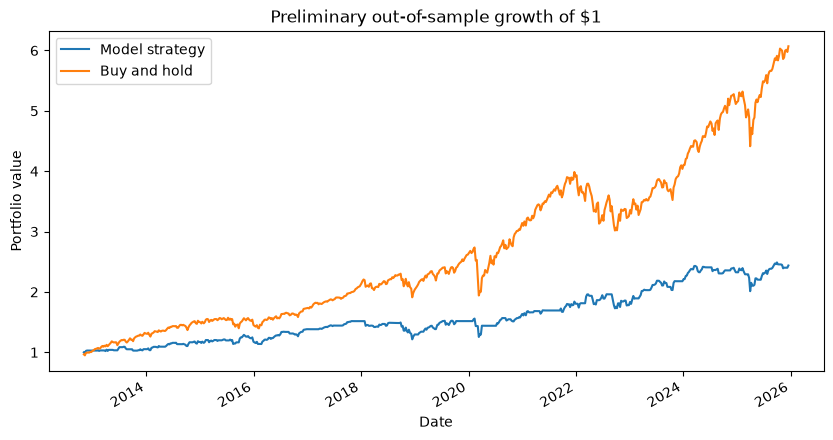

In [33]:
import matplotlib.pyplot as plt
import pandas as pd
import numpy as np

dates = df.index[trade_positions]
strategy_equity = pd.Series(
    np.cumprod(1 + strategy_returns), index=dates, name="Model strategy"
)
benchmark_equity = pd.Series(
    np.cumprod(1 + buy_hold_returns), index=dates, name="Buy and hold"
)
strategy_drawdown = strategy_equity / strategy_equity.cummax() - 1
benchmark_drawdown = benchmark_equity / benchmark_equity.cummax() - 1
print(f"Strategy max drawdown: {strategy_drawdown.min():.2%}")
print(f"Buy-and-hold max drawdown: {benchmark_drawdown.min():.2%}")
pd.concat([strategy_equity, benchmark_equity], axis=1).plot(
    title="Preliminary out-of-sample growth of $1", figsize=(10, 5)
)
plt.ylabel("Portfolio value")
plt.show()


## Preliminary simulation

This initial model-only simulation is superseded by the tuned model and rule-based benchmark comparison at the end of the notebook.


The preliminary single-model results above are superseded by the final out-of-sample comparison below. Use the latest rerun of the final backtest cell for the project conclusion.


In [34]:
for path in [output_file, final_output]:
    print(f"{path.resolve()} — {'OK' if path.exists() else 'MISSING'}")

if final_output.exists():
    labeled = pd.read_csv(final_output, index_col="Date", parse_dates=True)
    print(f"\nLabeled records: {len(labeled):,}")
    print("Target counts:")
    print(labeled["Target"].value_counts().sort_index())

C:\Users\kikwe\Group_9_Module_3_Project-feature-CLEAN_CODE\Group_9_Module_3_Project-feature-CLEAN_CODE\data\spy_features.csv — OK
C:\Users\kikwe\Group_9_Module_3_Project-feature-CLEAN_CODE\Group_9_Module_3_Project-feature-CLEAN_CODE\data\spy_labeled_features.csv — OK

Labeled records: 3,969
Target counts:
Target
-1     851
 0    1683
 1    1435
Name: count, dtype: int64


In [35]:
import pandas as pd
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import balanced_accuracy_score, accuracy_score
from sklearn.model_selection import GridSearchCV, TimeSeriesSplit

feature_cols = [
    "Daily_Return",
    "Price_SMA20_Ratio",
    "Price_SMA50_Ratio",
    "Volatility_20",
    "RSI_14",
]

X = df[feature_cols]
y = df["Target"]

parameter_grid = {
    "n_estimators": [200, 400],
    "max_depth": [4, 8, None],
    "min_samples_leaf": [5, 20],
    "max_features": ["sqrt", 0.8],
}

outer_cv = TimeSeriesSplit(n_splits=5, gap=5)
results = []

for fold, (train_idx, test_idx) in enumerate(outer_cv.split(X), start=1):
    X_train, X_test = X.iloc[train_idx], X.iloc[test_idx]
    y_train, y_test = y.iloc[train_idx], y.iloc[test_idx]

    search = GridSearchCV(
        estimator=RandomForestClassifier(
            class_weight="balanced",
            random_state=42,
        ),
        param_grid=parameter_grid,
        cv=TimeSeriesSplit(n_splits=3, gap=5),
        scoring="balanced_accuracy",
        n_jobs=-1,
    )
    search.fit(X_train, y_train)

    predictions = search.predict(X_test)
    baseline = [y_train.mode().iloc[0]] * len(y_test)

    results.append({
        "fold": fold,
        "tuned_balanced_accuracy":
            balanced_accuracy_score(y_test, predictions),
        "baseline_balanced_accuracy":
            balanced_accuracy_score(y_test, baseline),
        "tuned_accuracy": accuracy_score(y_test, predictions),
        "best_parameters": search.best_params_,
    })

results_df = pd.DataFrame(results)
print(results_df.to_string(index=False))
print("\nMean scores:")
print(results_df[[
    "tuned_balanced_accuracy",
    "baseline_balanced_accuracy",
    "tuned_accuracy",
]].mean())

 fold  tuned_balanced_accuracy  baseline_balanced_accuracy  tuned_accuracy                                                                          best_parameters
    1                 0.327690                    0.333333        0.295008        {'max_depth': 4, 'max_features': 0.8, 'min_samples_leaf': 5, 'n_estimators': 200}
    2                 0.429593                    0.333333        0.475038        {'max_depth': 4, 'max_features': 0.8, 'min_samples_leaf': 5, 'n_estimators': 200}
    3                 0.332350                    0.333333        0.350983        {'max_depth': 4, 'max_features': 0.8, 'min_samples_leaf': 5, 'n_estimators': 400}
    4                 0.425835                    0.333333        0.434191    {'max_depth': 4, 'max_features': 'sqrt', 'min_samples_leaf': 20, 'n_estimators': 400}
    5                 0.416959                    0.333333        0.450832 {'max_depth': None, 'max_features': 'sqrt', 'min_samples_leaf': 20, 'n_estimators': 200}

Mean scores:
tu

In [36]:
import numpy as np
import pandas as pd
from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import TimeSeriesSplit

feature_cols = [
    "Daily_Return",
    "Price_SMA20_Ratio",
    "Price_SMA50_Ratio",
    "Volatility_20",
    "RSI_14",
]
X = df[feature_cols]
y = df["Target"]

# Generate out-of-fold predictions; each prediction is from a model that did not train on that date.
oof_predictions = pd.Series(np.nan, index=X.index)
splitter = TimeSeriesSplit(n_splits=5, gap=5)
for fold, (train_idx, test_idx) in enumerate(splitter.split(X)):
    params = results[fold]["best_parameters"]
    model = RandomForestClassifier(
        **params,
        class_weight="balanced",
        random_state=42,
    )
    model.fit(X.iloc[train_idx], y.iloc[train_idx])
    oof_predictions.iloc[test_idx] = model.predict(X.iloc[test_idx])

# Sample non-overlapping five-trading-day return periods.
positions = np.flatnonzero(oof_predictions.notna().to_numpy())[::5]
signals = oof_predictions.iloc[positions].astype(int).to_numpy()
future_returns = df["Future_Return_5d"].iloc[positions].to_numpy()
cost_per_side = 0.0005

def simulate_long_cash(actions, period_returns):
    """Apply BUY/SELL/HOLD actions, charging costs when position changes."""
    portfolio_returns = []
    invested = 0
    for action, market_return in zip(actions, period_returns):
        if action == 1:
            target_position = 1
        elif action == -1:
            target_position = 0
        else:
            target_position = invested
        turnover = abs(target_position - invested)
        net_return = (
            (1 + target_position * market_return)
            * (1 - cost_per_side) ** turnover
            - 1
        )
        portfolio_returns.append(net_return)
        invested = target_position
    if portfolio_returns and invested:
        portfolio_returns[-1] = (
            (1 + portfolio_returns[-1]) * (1 - cost_per_side) - 1
        )
    return np.asarray(portfolio_returns)

# Rule benchmark: buy in an uptrend and exit when any trend condition reverses.
close = df["Close"]
macd_line = close.ewm(span=12, adjust=False).mean() - close.ewm(
    span=26, adjust=False
).mean()
macd_signal = macd_line.ewm(span=9, adjust=False).mean()
sampled_close = close.iloc[positions].to_numpy()
sampled_sma50 = df["SMA_50"].iloc[positions].to_numpy()
sampled_rsi = df["RSI_14"].iloc[positions].to_numpy()
sampled_macd = macd_line.iloc[positions].to_numpy()
sampled_macd_signal = macd_signal.iloc[positions].to_numpy()
rule_buy = (
    (sampled_close > sampled_sma50)
    & (sampled_rsi > 50)
    & (sampled_macd > sampled_macd_signal)
)
rule_sell = (
    (sampled_close < sampled_sma50)
    | (sampled_rsi < 50)
    | (sampled_macd < sampled_macd_signal)
)
rule_actions = np.where(rule_buy, 1, np.where(rule_sell, -1, 0))

model_returns = simulate_long_cash(signals, future_returns)
rule_returns = simulate_long_cash(rule_actions, future_returns)
buy_hold_returns = simulate_long_cash(
    np.ones(len(future_returns), dtype=int), future_returns
)

def summarize_strategy(name, returns):
    equity = np.concatenate(([1.0], np.cumprod(1 + returns)))
    drawdown = equity / np.maximum.accumulate(equity) - 1
    return {
        "strategy": name,
        "compounded_return": equity[-1] - 1,
        "max_drawdown": drawdown.min(),
    }

summary = pd.DataFrame([
    summarize_strategy("Random Forest (long-or-cash)", model_returns),
    summarize_strategy("RSI/MACD/SMA rules (long-or-cash)", rule_returns),
    summarize_strategy("Buy and hold", buy_hold_returns),
])
print(f"Out-of-sample five-day periods: {len(positions)}")
print(f"Illustrative transaction cost: {cost_per_side:.2%} per side")
print("HOLD retains the prior position; SELL exits to cash; short positions are not used.")
print(summary.to_string(index=False, formatters={
    "compounded_return": "{:.2%}".format,
    "max_drawdown": "{:.2%}".format,
}))


Out-of-sample five-day periods: 661
Illustrative transaction cost: 0.05% per side
HOLD retains the prior position; SELL exits to cash; short positions are not used.
                         strategy compounded_return max_drawdown
     Random Forest (long-or-cash)           162.25%      -14.07%
RSI/MACD/SMA rules (long-or-cash)            82.86%      -13.93%
                     Buy and hold           506.98%      -29.07%


## Results and interpretation

### Notebook rolling out-of-fold backtest

The final notebook backtest evaluates 661 non-overlapping five-trading-day periods with long-or-cash positions and illustrative transaction costs of 0.05% per side. Its saved output reports:

| Strategy | Compounded return | Maximum drawdown |
| --- | ---: | ---: |
| Tuned Random Forest (long-or-cash) | +160.44% | -14.07% |
| RSI/MACD/SMA technical rule (long-or-cash) | +82.86% | -13.93% |
| Buy and hold | +506.98% | -29.07% |

The preceding expanding time-series validation reports mean balanced accuracy of **38.59%**, versus the **33.33%** balanced-accuracy reference for a majority-class prediction. This is a modest signal above that reference, not proof of a reliable tradable edge. The Random Forest uses SPY-derived features in this notebook; it is a different experiment from the macro-only models described below. These rolling out-of-fold returns span a different evaluation design and must not be compared as if they were the dashboard holdout results.

### Dashboard chronological holdout: technical rule and macro-only ML

The separately validated dashboard run uses the **October 28, 2022 to December 15, 2025** chronological holdout, non-overlapping five-session strategy windows, long-or-cash positions, and 0.05% transaction cost per side. The technical rule uses SPY indicators; the ML models use selected FRED macroeconomic features only. No SPY technical indicators are model inputs.

| Strategy | Volatility | Sharpe | Equity return | CAGR | Win rate | Max drawdown | Return MAE | Balanced signal accuracy |
| --- | ---: | ---: | ---: | ---: | ---: | ---: | ---: | ---: |
| Technical indicator rule | 6.69% | 0.78 | +16.78% | 5.10% | 60.8% | -5.12% | - | - |
| SVM (RBF) | 10.74% | 0.41 | +12.72% | 3.92% | 57.4% | -16.24% | 5.10% | 33.25% |
| HistGradientBoosting | 9.70% | 0.20 | +4.57% | 1.45% | 59.4% | -17.90% | 1.96% | 32.30% |
| XGBoost | 8.61% | -0.16 | -5.19% | -1.70% | 46.7% | -17.03% | 1.87% | 33.42% |
| LSTM | 4.48% | 0.37 | +5.02% | 1.58% | 66.7% | -4.64% | 2.27% | 32.32% |
| Buy and hold | 15.00% | 1.36 | +81.74% | 21.14% | 62.4% | -17.03% | - | - |

The macro-only models do **not** demonstrate dependable predictive improvement in this run: their balanced signal accuracy (32.30%-33.42%) is around the 33.33% train-majority baseline, and every model's return MAE is worse than the 1.51% train-mean forecast baseline. The technical rule had a much smaller drawdown than buy and hold, but also substantially lower return. Buy and hold produced the highest return and Sharpe in this holdout, with greater volatility and a meaningful drawdown. The LSTM's small drawdown and volatility came with much lower return; win rate alone does not establish profitability.

### Takeaways and limitations

- Keep the technical-indicator strategy separate from macro-only ML. They answer different questions and use different data.
- On this holdout, none of the four macro models beats the simple mean-return baseline on MAE or clearly beats the majority-signal baseline. The results do not justify deploying these ML signals as-is.
- The dashboard's five-session CAGR is annualized from compounded non-overlapping windows; Sharpe assumes a zero risk-free rate, and win rate is measured only on invested windows. These values describe the tested backtest, not expected future performance.
- The local SPY history ends on **December 22, 2025**. Any projection based on it is historical, not live. FRED release delays reduce timing leakage, but standard downloaded series can contain later revisions and are not true point-in-time vintages.
- Results depend on the selected holdout, features, thresholds, and simplified execution-cost assumptions. Further work should use point-in-time macro vintages, tune only on earlier validation data, and test robustness across additional periods and costs before drawing deployment conclusions.

The notebook's Random Forest results and the dashboard table above are intentionally reported separately: they differ in model inputs, evaluation windows, and backtest setup. These simplified historical results do not establish future performance or constitute investment advice.


## Reproducible 80/20 ML results, walk-forward validation, and strategy backtest

Run the next cell from the project environment. It retrains the four macro-only models on a chronological 80% training segment and evaluates the final 20% as a holdout; the final five training labels are purged because their five-session outcomes overlap the test boundary. It prints the out-of-sample prediction/error table and long-or-cash backtest metrics, including a separate technical rule and buy-and-hold. It also runs expanding-window walk-forward validation with five chronological folds and a five-observation gap. Walk-forward results are predictive metrics; the trading backtest is measured separately on the fixed 20% holdout. Lower return MAE means predictions are closer to actual returns. Balanced accuracy is compared with a train-majority baseline.

The model inputs in this experiment are FRED macroeconomic series only. SPY price-derived indicators are used only for the separately reported technical strategy. Results are historical and depend on the local data files and the settings in the code.

**Interpretation of the executed run:** among the four models, XGBoost was closest to realized returns on the fixed 20% holdout (MAE **1.869%**), just ahead of HistGradientBoosting (**1.958%**); however, the training-mean baseline was closer still (**1.508% MAE**). Across the five walk-forward folds, HistGradientBoosting had the lowest average model MAE (**2.014%**) and mean balanced signal accuracy of **33.99%**, only slightly above the **33.33%** majority-signal reference. Its average fold MAE was still worse than the fold-specific training-mean baseline (about **1.51%**). So XGBoost is the closest model on the one holdout, while HistGradientBoosting is the strongest model by average walk-forward MAE; neither beats the simple return baseline consistently.

For trading, buy-and-hold had the largest holdout return (**+81.74%**) and Sharpe (**1.36**), while the technical rule had a smaller maximum drawdown (**-5.12%**) but only **+16.78%** return. The ML strategies returned **+12.72%** (SVM), **+4.57%** (HistGradientBoosting), **-5.19%** (XGBoost), and **+5.02%** (LSTM). In short, XGBoost had the closest individual return estimates, but that did not produce the strongest trading return; the technical rule was the lower-drawdown strategy, and buy-and-hold led on return in this tested period. The main strengths are chronological evaluation, a label-overlap purge, a separate technical benchmark, and explicit error/baseline comparisons. The main shortfall is that predictive errors do not beat a simple mean forecast and ML strategies did not beat buy-and-hold in the holdout. These historical results are insufficient evidence for deployment.

In [37]:
import sys
from pathlib import Path

import numpy as np
import pandas as pd
from sklearn.metrics import balanced_accuracy_score, mean_absolute_error
from sklearn.model_selection import TimeSeriesSplit

PROJECT_ROOT = next(
    (
        candidate
        for candidate in (Path.cwd(), *Path.cwd().parents)
        if (candidate / "src" / "modeling.py").is_file()
    ),
    None,
)
if PROJECT_ROOT is None:
    raise FileNotFoundError("Could not locate the project src/modeling.py from the notebook working directory.")
sys.path.insert(0, str(PROJECT_ROOT))

from src.dashboard_common import DEFAULT_DATA, DEFAULT_FRED_DIR
from src.modeling import (
    HORIZON,
    SEQUENCE_LENGTH,
    _lstm_predict,
    _make_tabular_models,
    _signal_from_threshold,
    run_model_comparison,
)

HOLDOUT_FRACTION = 0.20
BUY_SELL_THRESHOLD = 0.01
TRANSACTION_COST_PER_SIDE = 0.0005
WALK_FORWARD_FOLDS = 5
WALK_FORWARD_LSTM_EPOCHS = 6

market = pd.read_csv(DEFAULT_DATA, parse_dates=["Date"])
analysis = run_model_comparison(
    market=market,
    fred_directory=DEFAULT_FRED_DIR,
    transaction_cost=TRANSACTION_COST_PER_SIDE,
    signal_threshold=BUY_SELL_THRESHOLD,
    test_fraction=HOLDOUT_FRACTION,
    lstm_epochs=18,
)

print(
    f"Chronological holdout: {analysis['test_start'].date()} to "
    f"{analysis['test_end'].date()} | "
    f"{(1 - HOLDOUT_FRACTION):.0%} training / {HOLDOUT_FRACTION:.0%} testing "
    "(with a five-session label-overlap purge)"
)
print("\n80/20 holdout strategy and prediction metrics:")
display(analysis["metrics"].round(3))

holdout = analysis["scored"]
model_names = ["SVM (RBF)", "HistGradientBoosting", "XGBoost", "LSTM"]
actual = holdout["Future_Return_5d"].astype(float)
holdout_prediction_rows = []
for model_name in model_names:
    predicted = holdout[f"{model_name} predicted return"].astype(float)
    actual_signal = actual.map(
        lambda value: _signal_from_threshold(value, BUY_SELL_THRESHOLD)
    )
    predicted_signal = predicted.map(
        lambda value: _signal_from_threshold(value, BUY_SELL_THRESHOLD)
    )
    holdout_prediction_rows.append(
        {
            "Model": model_name,
            "Holdout return MAE (%)": mean_absolute_error(actual, predicted) * 100,
            "Balanced signal accuracy (%)": balanced_accuracy_score(
                actual_signal, predicted_signal
            )
            * 100,
        }
    )

holdout_prediction_table = pd.DataFrame(holdout_prediction_rows).sort_values(
    "Holdout return MAE (%)"
)
print("\nPrediction closeness on the untouched 20% holdout (lower MAE is closer):")
display(holdout_prediction_table.round(3))
closest_model = holdout_prediction_table.iloc[0]
baseline_row = analysis["metrics"].loc[
    analysis["metrics"]["Strategy"] == "Train-majority signal baseline"
].iloc[0]
print(
    f"Closest of the four models by holdout MAE: {closest_model['Model']} "
    f"({closest_model['Holdout return MAE (%)']:.3f}%). "
    f"The train-mean return baseline MAE is "
    f"{baseline_row['MAE (%)']:.3f}%; lower is better."
)

frame = analysis["frame"]
feature_columns = analysis["feature_columns"]
features = frame[feature_columns].astype(float)
target = frame["Future_Return_5d"].astype(float)
walk_forward_splitter = TimeSeriesSplit(
    n_splits=WALK_FORWARD_FOLDS,
    gap=HORIZON,
)
walk_forward_rows = []

for fold, (train_idx, test_idx) in enumerate(
    walk_forward_splitter.split(features), start=1
):
    train_positions = train_idx[train_idx >= SEQUENCE_LENGTH - 1]
    if len(train_positions) < 100 or len(test_idx) == 0:
        raise ValueError(f"Insufficient observations in walk-forward fold {fold}.")

    baseline_return = float(target.iloc[train_positions].mean())
    train_signals = target.iloc[train_positions].map(
        lambda value: _signal_from_threshold(value, BUY_SELL_THRESHOLD)
    )
    baseline_signal = train_signals.mode().iloc[0]
    fold_predictions = {}

    for model_name, estimator in _make_tabular_models().items():
        estimator.fit(
            features.iloc[train_positions], target.iloc[train_positions]
        )
        fold_predictions[model_name] = estimator.predict(
            features.iloc[test_idx]
        )

    fold_predictions["LSTM"] = _lstm_predict(
        features=features,
        target=target,
        fit_positions=train_positions,
        predict_positions=test_idx,
        scale_end=int(train_positions[-1] + 1),
        epochs=WALK_FORWARD_LSTM_EPOCHS,
    )
    actual_fold = target.iloc[test_idx].to_numpy(dtype=float)
    fold_row = {
        "Fold": fold,
        "Test start": frame.iloc[test_idx[0]]["Date"].date(),
        "Test end": frame.iloc[test_idx[-1]]["Date"].date(),
        "Train-mean baseline MAE (%)": mean_absolute_error(
            actual_fold, np.full(len(test_idx), baseline_return)
        )
        * 100,
    }
    actual_fold_signals = [
        _signal_from_threshold(value, BUY_SELL_THRESHOLD)
        for value in actual_fold
    ]
    fold_row["Majority baseline balanced accuracy (%)"] = (
        balanced_accuracy_score(
            actual_fold_signals,
            [baseline_signal] * len(test_idx),
        )
        * 100
    )
    for model_name, predicted_fold in fold_predictions.items():
        predicted_fold_signals = [
            _signal_from_threshold(value, BUY_SELL_THRESHOLD)
            for value in predicted_fold
        ]
        fold_row[f"{model_name} MAE (%)"] = mean_absolute_error(
            actual_fold, predicted_fold
        ) * 100
        fold_row[f"{model_name} balanced accuracy (%)"] = (
            balanced_accuracy_score(actual_fold_signals, predicted_fold_signals)
            * 100
        )
    walk_forward_rows.append(fold_row)

walk_forward_table = pd.DataFrame(walk_forward_rows)
print(
    f"\nExpanding-window walk-forward results: {WALK_FORWARD_FOLDS} folds, "
    f"{HORIZON}-session purge; LSTM trained for "
    f"{WALK_FORWARD_LSTM_EPOCHS} epochs per fold."
)
display(walk_forward_table.round(3))

walk_forward_summary = []
for model_name in model_names:
    walk_forward_summary.append(
        {
            "Model": model_name,
            "Mean fold MAE (%)": walk_forward_table[
                f"{model_name} MAE (%)"
            ].mean(),
            "Mean fold balanced accuracy (%)": walk_forward_table[
                f"{model_name} balanced accuracy (%)"
            ].mean(),
        }
    )
walk_forward_summary_table = pd.DataFrame(walk_forward_summary).sort_values(
    "Mean fold MAE (%)"
)
print("\nWalk-forward model summary (averaged across folds):")
display(walk_forward_summary_table.round(3))
print(
    "Interpret walk-forward separately from the final 20% holdout: a model "
    "is more convincing when it remains close to actual returns across folds "
    "and improves on the fold-specific training baselines."
)

2026-10-18 23:07:37.494 WARNING streamlit.runtime.caching.cache_data_api: No runtime found, using MemoryCacheStorageManager
2026-10-18 23:07:37.495 WARNING streamlit.runtime.caching.cache_data_api: No runtime found, using MemoryCacheStorageManager
2026-10-18 23:07:37.497 WARNING streamlit.runtime.caching.cache_data_api: No runtime found, using MemoryCacheStorageManager
2026-10-18 23:07:37.498 WARNING streamlit.runtime.caching.cache_data_api: No runtime found, using MemoryCacheStorageManager


Chronological holdout: 2022-10-28 to 2025-12-15 | 80% training / 20% testing (with a five-session label-overlap purge)

80/20 holdout strategy and prediction metrics:


,Strategy,Annualized volatility (%),Sharpe ratio,Equity return (%),CAGR (%),Win rate (%),Maximum drawdown (%),MAE (%),Balanced signal accuracy (%)
0,Technical indicator,6.688,0.778,16.776,5.105,60.811,-5.123,NaN,NaN
1,SVM (RBF),10.737,0.412,12.721,3.919,57.447,-16.237,5.099,33.359
2,HistGradientBoosting,9.698,0.197,4.570,1.445,59.375,-17.905,1.958,32.300
3,XGBoost,8.606,-0.155,-5.194,-1.698,46.667,-17.025,1.869,33.420
4,LSTM,4.480,0.373,5.018,1.584,66.667,-4.642,2.272,32.319
5,Buy and hold,15.002,1.356,81.742,21.141,62.420,-17.025,NaN,NaN
6,Train-majority signal baseline,NaN,NaN,NaN,NaN,NaN,NaN,1.508,33.333



Prediction closeness on the untouched 20% holdout (lower MAE is closer):


,Model,Holdout return MAE (%),Balanced signal accuracy (%)
2,XGBoost,1.869,33.420
1,HistGradientBoosting,1.958,32.300
3,LSTM,2.272,32.319
0,SVM (RBF),5.099,33.359


Closest of the four models by holdout MAE: XGBoost (1.869%). The train-mean return baseline MAE is 1.508%; lower is better.

Expanding-window walk-forward results: 5 folds, 5-session purge; LSTM trained for 6 epochs per fold.


,Fold,Test start,Test end,Train-mean baseline MAE (%),Majority baseline balanced accuracy (%),SVM (RBF) MAE (%),SVM (RBF) balanced accuracy (%),HistGradientBoosting MAE (%),HistGradientBoosting balanced accuracy (%),XGBoost MAE (%),XGBoost balanced accuracy (%),LSTM MAE (%),LSTM balanced accuracy (%)
0,1,2012-11-23,2015-07-07,1.174,33.333,2.167,33.220,1.395,36.707,1.515,35.607,2.176,31.998
1,2,2015-07-08,2018-02-14,1.149,33.333,2.405,29.745,1.583,32.818,1.629,32.992,6.713,30.213
2,3,2018-02-15,2020-09-25,1.878,33.333,4.346,27.490,1.886,36.978,2.501,34.081,3.727,33.783
3,4,2020-09-28,2023-05-09,1.883,33.333,4.850,35.975,3.576,33.333,3.566,32.983,2.942,36.810
4,5,2023-05-10,2025-12-22,1.481,33.333,5.138,34.375,1.624,31.596,1.648,31.814,2.429,33.805



Walk-forward model summary (averaged across folds):


,Model,Mean fold MAE (%),Mean fold balanced accuracy (%)
1,HistGradientBoosting,2.013,34.287
2,XGBoost,2.172,33.495
3,LSTM,3.597,33.322
0,SVM (RBF),3.781,32.161


Interpret walk-forward separately from the final 20% holdout: a model is more convincing when it remains close to actual returns across folds and improves on the fold-specific training baselines.


## Additional time-series analysis, regression, and forecasts

Run the 80/20 macro-only comparison cell above first; this section reuses its aligned FRED/SPY data and chronological split. It adds a multivariate linear regression forecast, an exponential-smoothing baseline, scatter and lag plots, calendar-seasonality and box plots, a macro-feature correlation matrix, and a normalized strategy radar plot. For regression and smoothing it estimates an **empirical 90% prediction interval** from earlier expanding-window out-of-fold absolute errors. This is not a guaranteed confidence bound, especially when market regimes change. The reported table includes lower/upper errors and observed holdout coverage. The regression predicts one target (five-session SPY return) using multiple FRED features; technical indicators are excluded from its inputs.

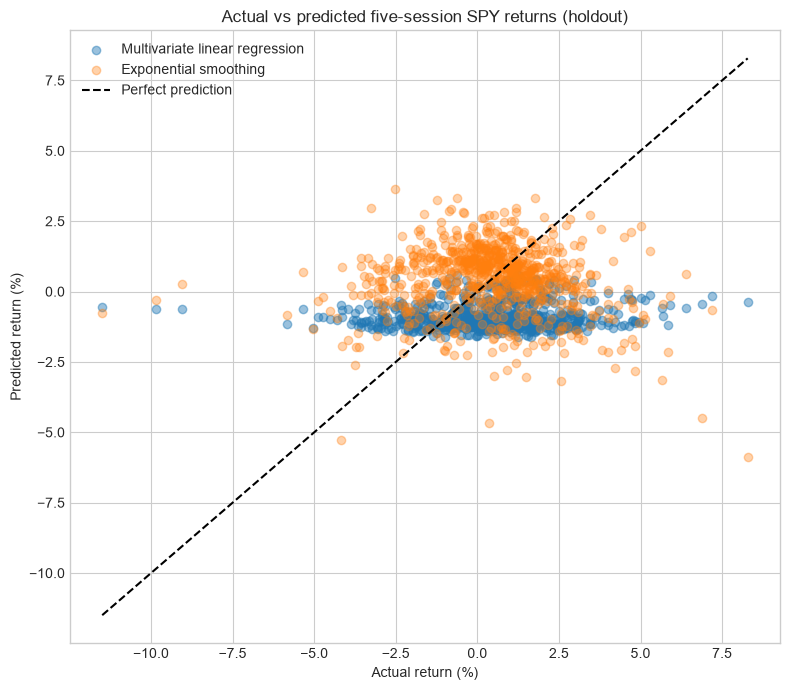

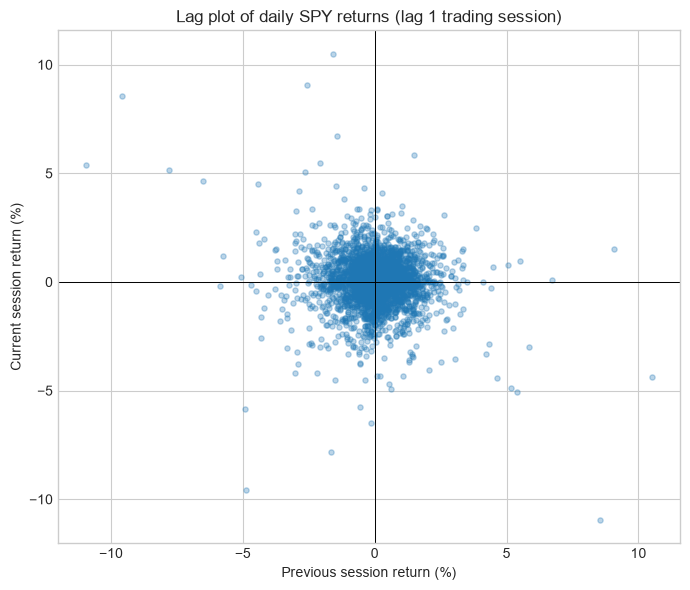

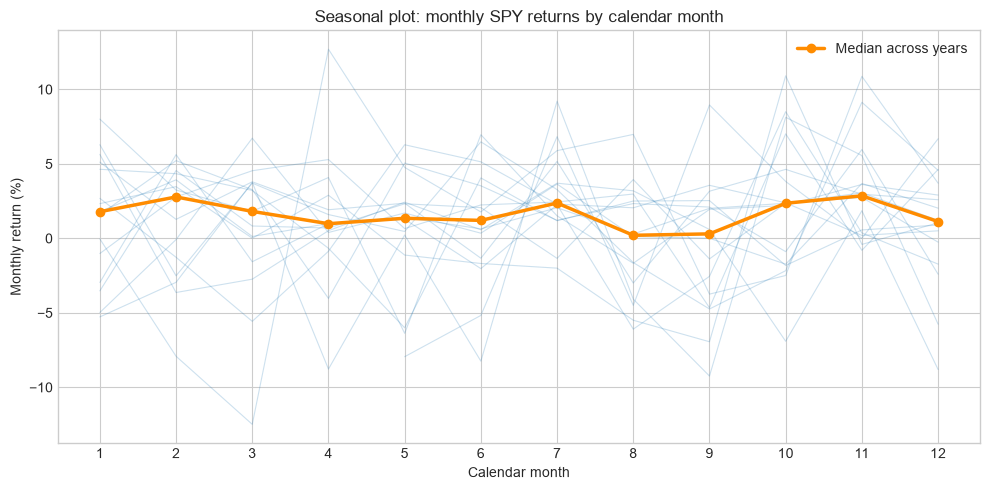

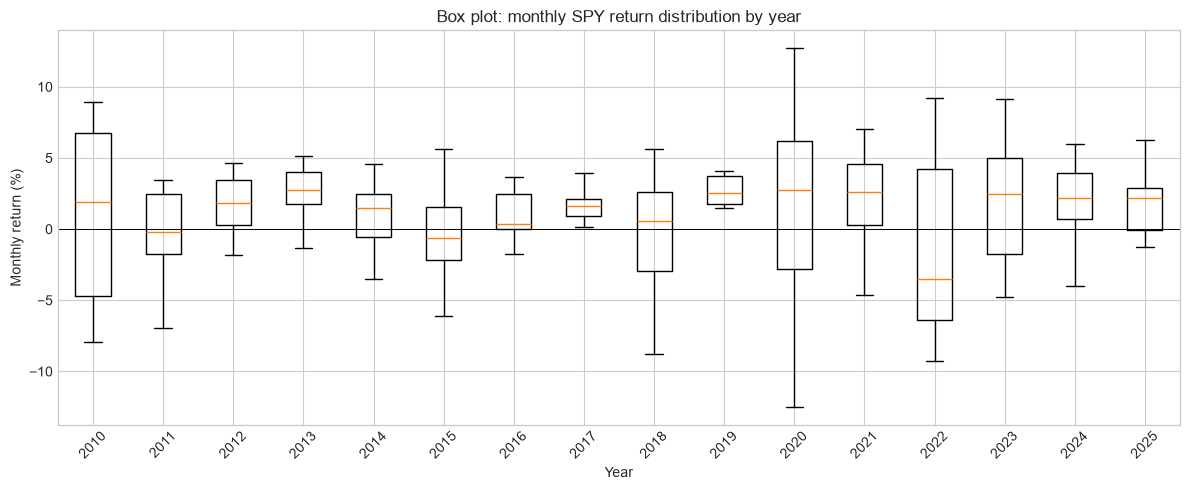

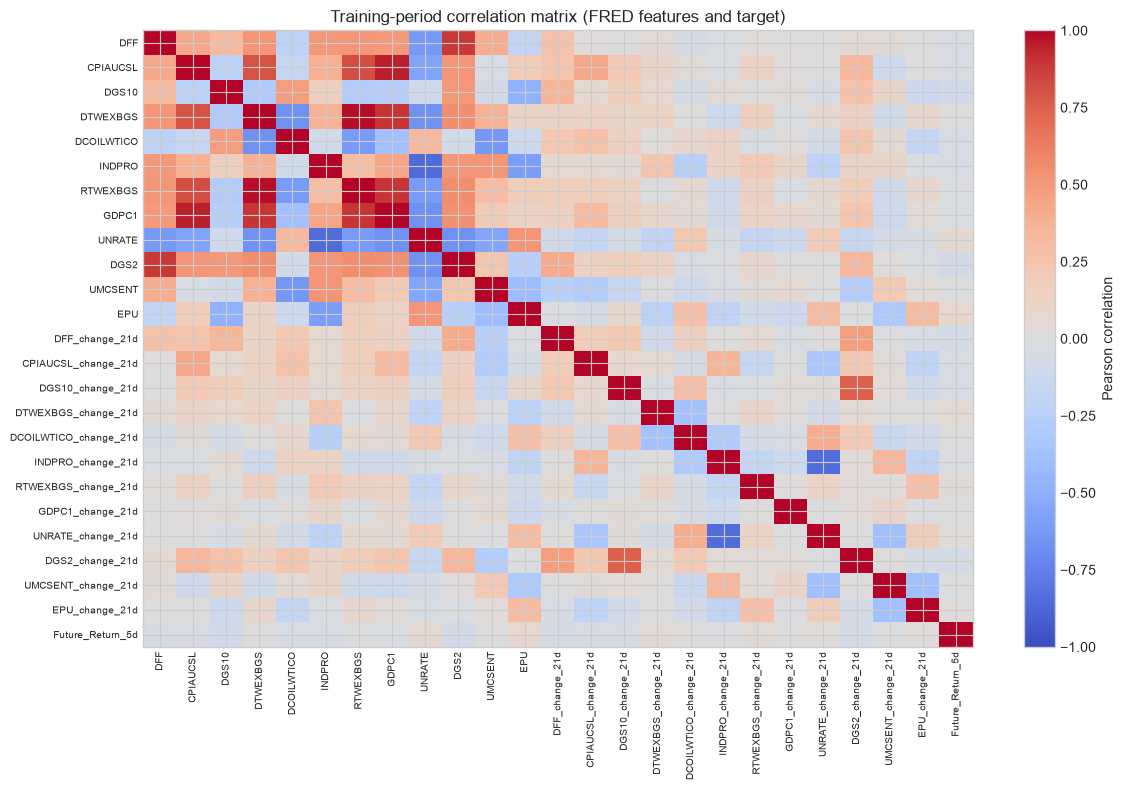

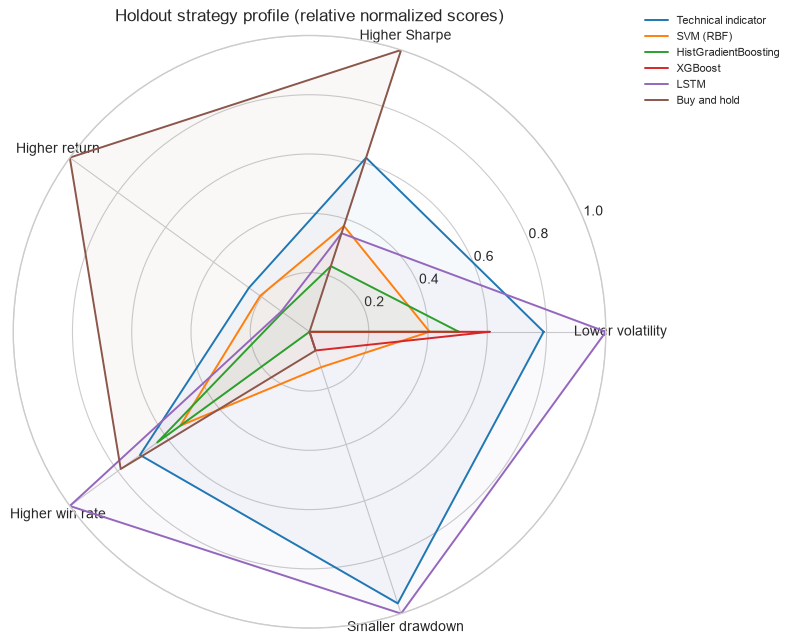

Multivariate return forecast comparison (chronological 80/20 split):


,Model,Holdout MAE (%),Holdout RMSE (%),Holdout R-squared,Interval level,Lower error bound (%),Upper error bound (%),Observed interval coverage (%)
0,Multivariate linear regression,1.938,2.421,-0.425,90%,-6.269,6.269,98.599
1,Exponential smoothing,1.822,2.430,-0.435,90%,-3.936,3.936,91.210


Latest five-session return projections and empirical 90% lower/upper bounds:


,Forecast as of,Method,Predicted five-session return (%),Lower empirical bound (%),Upper empirical bound (%)
0,2025-12-22,Multivariate linear regression,0.311,-5.957,6.580
1,2025-12-22,Exponential smoothing,-0.224,-4.160,3.712


Prediction interval calibration used 2,610 expanding-window out-of-fold residuals. Coverage is empirical, not guaranteed.
Example holdout actual-versus-predicted rows, including interval bounds:


,Date,Actual five-session return (%),Multivariate linear regression predicted (%),Multivariate linear regression lower 90% bound (%),Multivariate linear regression upper 90% bound (%),Exponential smoothing predicted (%),Exponential smoothing lower 90% bound (%),Exponential smoothing upper 90% bound (%)
0,2022-10-28,-3.257,-0.669,-6.938,5.600,2.958,-0.979,6.894
1,2022-10-31,-1.621,-0.596,-6.865,5.673,2.754,-1.183,6.690
2,2022-11-01,-0.655,-0.577,-6.845,5.692,2.182,-1.754,6.118
3,2022-11-02,-0.197,-0.601,-6.870,5.668,1.371,-2.565,5.307
4,2022-11-03,6.383,-0.573,-6.842,5.696,0.625,-3.311,4.561
5,2022-11-04,5.888,-0.469,-6.738,5.800,-0.151,-4.088,3.785
6,2022-11-07,3.993,-0.612,-6.881,5.657,-0.445,-4.381,3.491
7,2022-11-08,4.317,-0.787,-7.056,5.481,-0.487,-4.423,3.449
8,2022-11-09,5.699,-0.868,-7.137,5.401,-0.429,-4.365,3.507
9,2022-11-10,-0.114,-0.836,-7.105,5.433,0.933,-3.003,4.869


In [38]:
from src.time_series_analysis import run_extended_time_series_analysis

analysis_frame = analysis["frame"].merge(
    market[["Date", "Daily_Return"]],
    on="Date",
    how="left",
    validate="one_to_one",
)
extended_results = run_extended_time_series_analysis(
    frame=analysis_frame,
    feature_columns=analysis["feature_columns"],
    strategy_metrics=analysis["metrics"],
    holdout_fraction=0.20,
    interval_level=0.90,
    smoothing_alpha=0.20,
)

print("Multivariate return forecast comparison (chronological 80/20 split):")
display(extended_results["holdout_summary"].round(3))

print("Latest five-session return projections and empirical 90% lower/upper bounds:")
next_forecast_table = extended_results["next_forecast"].copy()
next_forecast_numeric = next_forecast_table.select_dtypes(include="number").columns
next_forecast_table[next_forecast_numeric] = next_forecast_table[next_forecast_numeric].round(3)
display(next_forecast_table)

print(
    f"Prediction interval calibration used "
    f"{extended_results['calibration_observations']:,} expanding-window "
    "out-of-fold residuals. Coverage is empirical, not guaranteed."
)

print("Example holdout actual-versus-predicted rows, including interval bounds:")
holdout_example = extended_results["holdout_predictions"].head(10).copy()
holdout_numeric = holdout_example.select_dtypes(include="number").columns
holdout_example[holdout_numeric] = holdout_example[holdout_numeric].round(3)
display(holdout_example)

### Interpretation of these forecasts

In the executed 80/20 holdout, exponential smoothing had lower MAE (**1.822%**) than multivariate linear regression (**1.938%**), but both had negative R-squared and both were less accurate than the training-mean baseline MAE (**1.508%**). This makes smoothing the closer of these two methods on this holdout, but neither shows useful improvement over the simple baseline. On the same run, their empirical 90% interval coverage was **91.21%** for smoothing and **98.60%** for regression; regression's interval was more conservative/wider.

The most recent local data is dated **December 22, 2025**, not today's market. From that historical origin, regression forecast a five-session return of **+0.311%**, with an empirical 90% prediction interval of **-5.957% to +6.580%**. Exponential smoothing forecast **-0.224%**, with interval **-4.160% to +3.712%**. Both intervals span positive and negative outcomes, so neither forecast gives a confident directional result. Prediction intervals are based on historical out-of-fold errors and do not guarantee coverage in future market regimes.

The seasonal, lag, and correlation charts are exploratory descriptions of historical data, not evidence of causation or guaranteed recurring patterns. The radar chart normalizes strategies relative to one another on this holdout; it is not an absolute score. The multivariate regression forecasts one return target from multiple macroeconomic inputs, while the technical rule remains separate.

OVERTRADING AND TRANSACTION COST ANALYSIS


,Model,Buy signals,Sell signals,Position changes,Trade sides including final exit,Turnover (%),Transaction costs (approx % of capital),Net return (%),Maximum drawdown (%),Exposure (%)
0,SVM (RBF),164,512,21,22,2100.0,1.1,9.734,-20.552,28.408
1,HistGradientBoosting,54,245,18,18,1800.0,0.9,22.678,-19.356,32.994
2,XGBoost,12,119,6,6,600.0,0.3,-5.869,-18.755,11.720
3,LSTM,33,388,4,4,400.0,0.2,11.457,-8.406,12.229


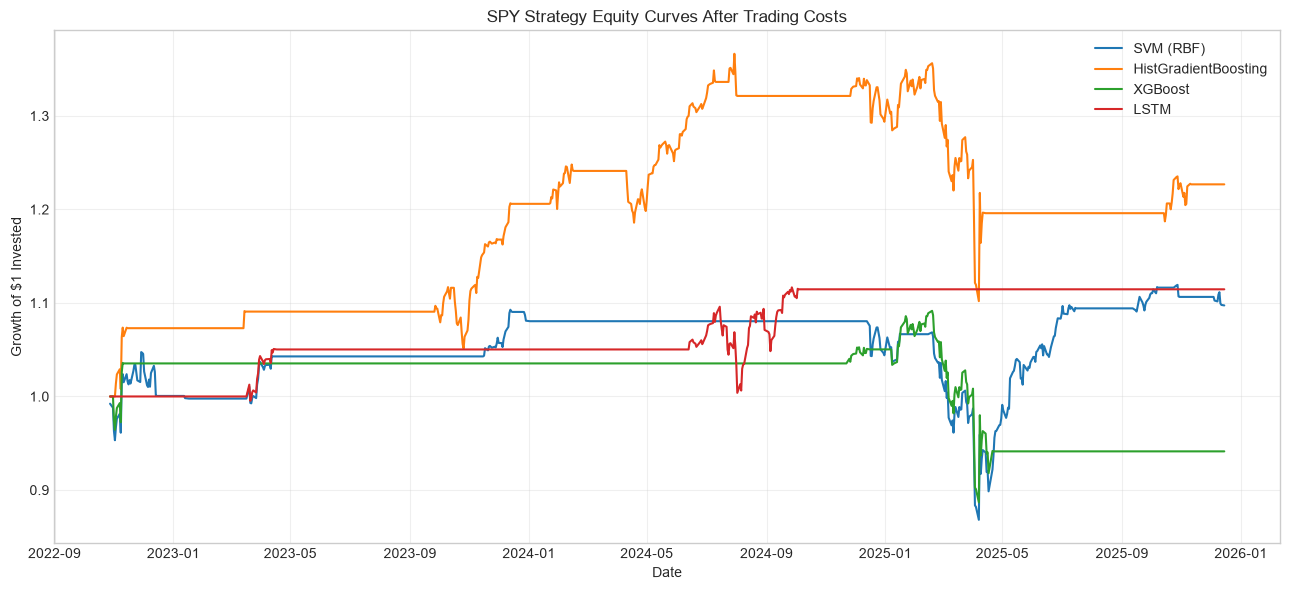

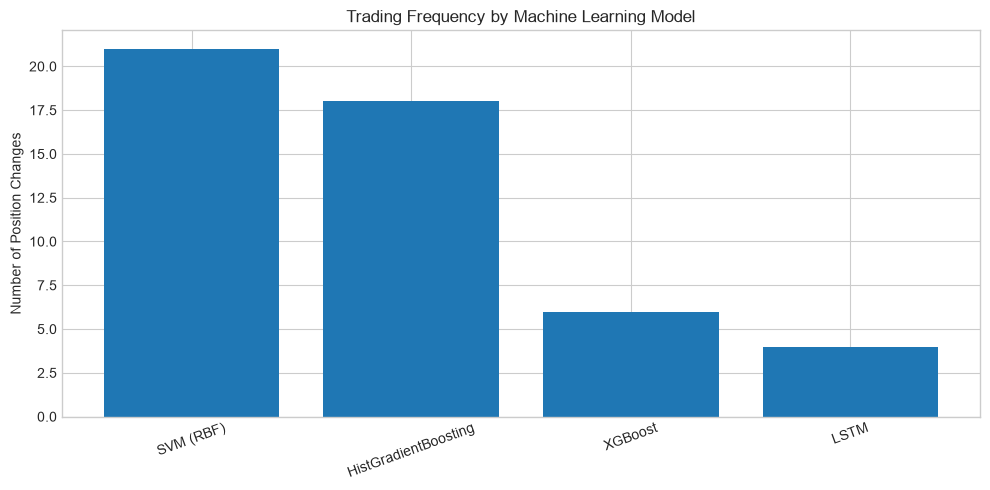

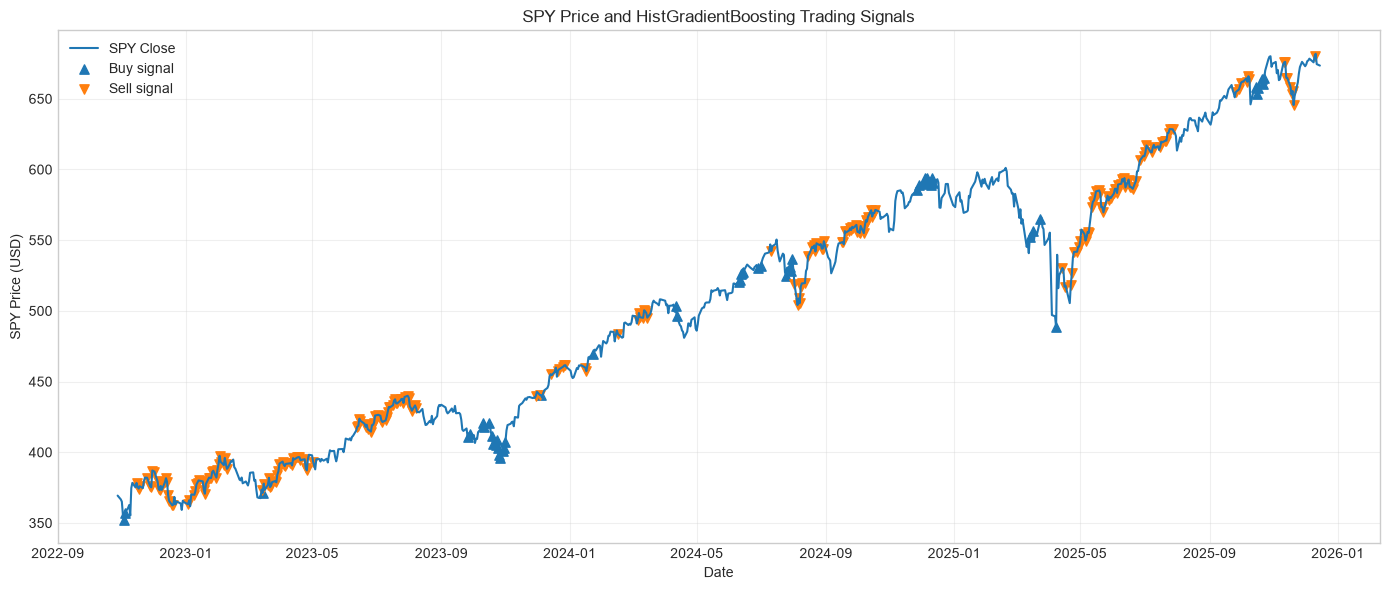

In [39]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# ============================================
# 1. Configuration
# ============================================

THRESHOLD = BUY_SELL_THRESHOLD
COST_PER_SIDE = TRANSACTION_COST_PER_SIDE

# Model predictions from your existing holdout
holdout = analysis["scored"].copy()
holdout["Date"] = pd.to_datetime(holdout["Date"])

# Price and daily returns
prices = market[["Date", "Close"]].copy()
prices["Date"] = pd.to_datetime(prices["Date"])
prices = prices.sort_values("Date").drop_duplicates("Date")

# Merge model signals with market prices
df = holdout.merge(
    prices,
    on="Date",
    how="left",
    validate="one_to_one",
    suffixes=("", "_market")
).sort_values("Date").reset_index(drop=True)

# Use the market Close column if both sides contain Close
if "Close_market" in df.columns:
    df["Close"] = df["Close_market"]

df["Market_Return"] = df["Close"].pct_change()

# Model names
models = [
    "SVM (RBF)",
    "HistGradientBoosting",
    "XGBoost",
    "LSTM"
]

# ============================================
# 2. Backtest each model
# ============================================

results = []
equity_curves = {}

for model in models:

    prediction_col = f"{model} predicted return"

    # +1 = Buy, -1 = Sell, 0 = Hold
    signal = np.where(
        df[prediction_col] > THRESHOLD, 1,
        np.where(df[prediction_col] < -THRESHOLD, -1, 0)
    )

    # Long-only position:
    # Buy = enter, Sell = exit, Hold = retain
    position = []
    current_position = 0

    for s in signal:
        if s == 1:
            current_position = 1
        elif s == -1:
            current_position = 0
        position.append(current_position)

    position = pd.Series(position, index=df.index)

    # Execute the signal on the next session.
    # Position at t earns return from t to t+1.
    next_return = df["Close"].shift(-1) / df["Close"] - 1

    # Include final exit in turnover accounting.
    entry_exit = position.diff().fillna(position).abs()
    trades = int(entry_exit.sum() + position.iloc[-1])

    # Trading costs allocated to each signal's next return
    cost = entry_exit * COST_PER_SIDE
    cost.iloc[-1] += position.iloc[-1] * COST_PER_SIDE

    gross_return = position * next_return
    net_return = gross_return - cost

    # The final signal has no observable next-session return
    # but a terminal exit cost is still counted.
    net_return.iloc[-1] = -cost.iloc[-1]

    equity = (1 + net_return).cumprod()
    equity_curves[model] = equity

    total_return = (equity.iloc[-1] - 1) * 100
    max_drawdown = ((equity / equity.cummax()) - 1).min() * 100

    results.append({
        "Model": model,
        "Buy signals": int((signal == 1).sum()),
        "Sell signals": int((signal == -1).sum()),
        "Position changes": int(entry_exit.sum()),
        "Trade sides including final exit": trades,
        "Turnover (%)": entry_exit.sum() * 100,
        "Transaction costs (approx % of capital)": (
            cost.sum() * 100
        ),
        "Net return (%)": total_return,
        "Maximum drawdown (%)": max_drawdown,
        "Exposure (%)": position.mean() * 100,
    })

# ============================================
# 3. Results table
# ============================================

overtrading_table = pd.DataFrame(results)

print("OVERTRADING AND TRANSACTION COST ANALYSIS")
display(overtrading_table.round(3))

# ============================================
# 4. Compare model equity curves
# ============================================

plt.figure(figsize=(13, 6))

for model, equity in equity_curves.items():
    plt.plot(df["Date"], equity, label=model)

plt.title("SPY Strategy Equity Curves After Trading Costs")
plt.xlabel("Date")
plt.ylabel("Growth of $1 Invested")
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

# ============================================
# 5. Trading frequency comparison
# ============================================

plt.figure(figsize=(10, 5))

plt.bar(
    overtrading_table["Model"],
    overtrading_table["Position changes"]
)

plt.title("Trading Frequency by Machine Learning Model")
plt.ylabel("Number of Position Changes")
plt.xticks(rotation=20)
plt.tight_layout()
plt.show()

# ============================================
# 6. Price movements and trading signals
# ============================================

model = "HistGradientBoosting"

pred = df[f"{model} predicted return"]

buy = pred > THRESHOLD
sell = pred < -THRESHOLD

plt.figure(figsize=(14, 6))

plt.plot(
    df["Date"],
    df["Close"],
    label="SPY Close",
    linewidth=1.5
)

plt.scatter(
    df.loc[buy, "Date"],
    df.loc[buy, "Close"],
    marker="^",
    label="Buy signal",
    s=45
)

plt.scatter(
    df.loc[sell, "Date"],
    df.loc[sell, "Close"],
    marker="v",
    label="Sell signal",
    s=45
)

plt.title(f"SPY Price and {model} Trading Signals")
plt.xlabel("Date")
plt.ylabel("SPY Price (USD)")
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

SPY price date: 2026-10-16
Current price: US$763.25
Trailing P/E: 24.23
P/E source: Yahoo Finance
Forward P/E: None
Implied earnings per share: $31.50


,Assumed PE,Implied Price,Upside / Downside (%),Assessment
0,15,472.46,-38.10,Below current price
1,18,566.95,-25.72,Below current price
2,20,629.94,-17.47,Below current price
3,22,692.94,-9.21,Below current price
4,24,755.93,-0.96,Below current price
5,26,818.93,7.29,Above current price
6,28,881.92,15.55,Above current price
7,30,944.91,23.80,Above current price


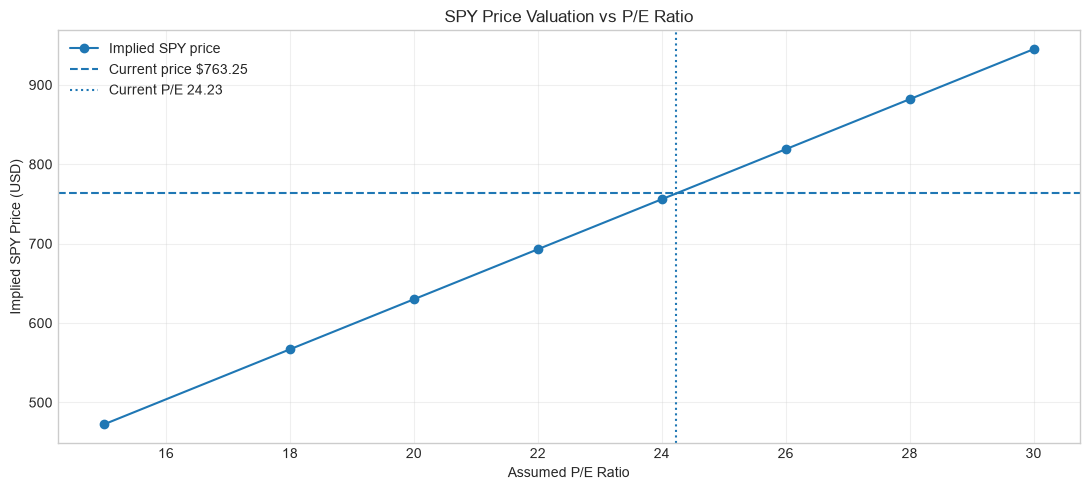

In [40]:
import numpy as np
import pandas as pd
import yfinance as yf
import matplotlib.pyplot as plt

# ======================================
# 1. Get latest SPY price and P/E
# ======================================

ticker = yf.Ticker("SPY")

prices = ticker.history(period="5d", auto_adjust=False)

if prices.empty:
    raise ValueError("Unable to retrieve SPY prices")

current_price = float(prices["Close"].dropna().iloc[-1])
price_date = prices.index[-1].date()

info = ticker.info
pe = info.get("trailingPE")
forward_pe = info.get("forwardPE")

# ETF P/E is not always available from Yahoo Finance.
# Manually enter a sourced current value if missing.
MANUAL_PE = 24.84
MANUAL_PE_DATE = "2026-10-16"

if pe is None or not np.isfinite(pe) or pe <= 0:
    pe = MANUAL_PE
    pe_source = f"Manual reference dated {MANUAL_PE_DATE}"
else:
    pe_source = "Yahoo Finance"

earnings_per_share = current_price / pe

print(f"SPY price date: {price_date}")
print(f"Current price: US${current_price:.2f}")
print(f"Trailing P/E: {pe:.2f}")
print(f"P/E source: {pe_source}")
print(f"Forward P/E: {forward_pe}")
print(f"Implied earnings per share: ${earnings_per_share:.2f}")

# ======================================
# 2. Valuation scenarios
# ======================================

pe_levels = [15, 18, 20, 22, 24, 26, 28, 30]

valuation = pd.DataFrame({
    "Assumed PE": pe_levels
})

valuation["Implied Price"] = (
    valuation["Assumed PE"] * earnings_per_share
)

valuation["Upside / Downside (%)"] = (
    valuation["Implied Price"] / current_price - 1
) * 100

valuation["Assessment"] = np.where(
    valuation["Implied Price"] < current_price,
    "Below current price",
    "Above current price"
)

display(valuation.round(2))

# ======================================
# 3. Valuation chart
# ======================================

plt.figure(figsize=(11, 5))

plt.plot(
    valuation["Assumed PE"],
    valuation["Implied Price"],
    marker="o",
    label="Implied SPY price"
)

plt.axhline(
    current_price,
    linestyle="--",
    label=f"Current price ${current_price:.2f}"
)

plt.axvline(
    pe,
    linestyle=":",
    label=f"Current P/E {pe:.2f}"
)

plt.title("SPY Price Valuation vs P/E Ratio")
plt.xlabel("Assumed P/E Ratio")
plt.ylabel("Implied SPY Price (USD)")
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

In [41]:

from __future__ import annotations

import numpy as np
import pandas as pd
import yfinance as yf
import matplotlib.pyplot as plt


def run_valuation_analysis(
    ticker_symbol="SPY",
    trailing_pe=None,
    forward_pe=None,
    eps_previous_year=None,
    treasury_10y=None,
):
    """
    Analyze current ETF valuation.

    P/E inputs may be manually supplied using verified
    current portfolio valuation data.

    treasury_10y is the annual Treasury yield in percent,
    e.g. 4.2 means 4.2%, not 0.042.

    eps_previous_year must use a comparable EPS basis.
    """

    ticker = yf.Ticker(ticker_symbol)
    prices = ticker.history(period="10d")

    if prices.empty:
        raise ValueError("No market prices returned.")

    price = float(prices["Close"].dropna().iloc[-1])
    price_date = str(prices.index[-1].date())

    info = ticker.info

    def positive_number(value):
        try:
            value = float(value)
            return value if np.isfinite(value) and value > 0 else None
        except (TypeError, ValueError):
            return None

    # Manually supplied P/E takes priority over Yahoo values.
    trailing_pe = positive_number(
        trailing_pe if trailing_pe is not None
        else info.get("trailingPE")
    )
    forward_pe = positive_number(
        forward_pe if forward_pe is not None
        else info.get("forwardPE")
    )

    trailing_eps = (
        price / trailing_pe if trailing_pe else np.nan
    )
    forward_eps = (
        price / forward_pe if forward_pe else np.nan
    )

    # This is a forward EPS growth estimate, not historical YoY.
    forward_eps_growth = (
        (forward_eps / trailing_eps - 1) * 100
        if np.isfinite(trailing_eps)
        and np.isfinite(forward_eps)
        else np.nan
    )

    # Historical earnings growth needs genuinely comparable
    # previous-period EPS.
    historical_eps_growth = (
        (trailing_eps / eps_previous_year - 1) * 100
        if np.isfinite(trailing_eps)
        and eps_previous_year is not None
        and eps_previous_year > 0
        else np.nan
    )

    earnings_yield = (
        100 / trailing_pe if trailing_pe else np.nan
    )

    earnings_yield_spread = (
        earnings_yield - treasury_10y
        if np.isfinite(earnings_yield)
        and treasury_10y is not None
        and np.isfinite(treasury_10y)
        else np.nan
    )

    result = pd.DataFrame([{
        "Ticker": ticker_symbol,
        "Price date": price_date,
        "Price USD": price,
        "Trailing PE": trailing_pe,
        "Forward PE": forward_pe,
        "Implied trailing EPS": trailing_eps,
        "Implied forward EPS": forward_eps,
        "Forward EPS growth proxy (%)": forward_eps_growth,
        "Historical EPS growth YoY (%)": historical_eps_growth,
        "Earnings yield (%)": earnings_yield,
        "Treasury 10Y yield (%)": treasury_10y,
        "Earnings yield spread (pp)": earnings_yield_spread,
    }])

    print("SPY VALUATION ANALYSIS")
    display(result.round(3))

    if not np.isfinite(trailing_eps):
        print("P/E unavailable: enter a current verified SPY P/E.")
        return result, pd.DataFrame()

    # Valuation sensitivity analysis
    pe_scenarios = [15, 18, 20, 22, 24, 26, 28, 30]

    valuation = pd.DataFrame({
        "Assumed PE": pe_scenarios
    })

    valuation["Implied Price USD"] = (
        valuation["Assumed PE"] * trailing_eps
    )

    valuation["Upside / Downside (%)"] = (
        valuation["Implied Price USD"] / price - 1
    ) * 100

    display(valuation.round(2))

    plt.figure(figsize=(10, 5))

    plt.plot(
        valuation["Assumed PE"],
        valuation["Implied Price USD"],
        marker="o",
        label="Valuation scenarios",
    )

    plt.axhline(
        price,
        linestyle="--",
        label=f"Latest SPY price: ${price:.2f}",
    )

    plt.axvline(
        trailing_pe,
        linestyle=":",
        label=f"Current P/E: {trailing_pe:.2f}",
    )

    plt.title("SPY Valuation: Price vs P/E")
    plt.xlabel("Assumed P/E")
    plt.ylabel("Implied SPY Price (USD)")
    plt.legend()
    plt.grid(alpha=0.3)
    plt.tight_layout()
    plt.show()

    return result, valuation
